# DATA 266 - Homework 2 - Spring 2026
## Prompt Engineering for Tabular Prediction + Enterprise RAG with WixQA

**Models Used:**
- Model 1: GPT-4.1 (gpt-4-1)
- Model 2: GPT-4o (gpt-4o)

**Datasets:**
- Task 1: Titanic (via seaborn - no download needed)
- Task 2: WixQA (via HuggingFace - no download needed)

---
# STEP 0: SETUP & INSTALLATIONS

In [ ]:
# Install all required libraries
!pip install openai datasets faiss-cpu sentence-transformers \
             rouge-score scikit-learn pandas numpy matplotlib seaborn tqdm \
             langchain langchain-community tiktoken transformers torch --quiet

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 82.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 115.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 51.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 503.0/503.0 kB 51.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.7/64.7 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.0/51.0 kB 6.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.32.5 which is incompatible.


In [ ]:
# Install required packages
!pip install openai google-generativeai scikit-learn pandas numpy matplotlib seaborn tqdm rouge-score -q

In [ ]:
# Mount Google Drive (for saving outputs and checkpoints)
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
from google.colab import userdata

os.environ['OPENAI_API_KEY'] = userdata.get('OPENAI_API_KEY')
print('OpenAI API key loaded successfully.')

OpenAI API key loaded successfully.


In [ ]:
import os
import json
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from collections import Counter

import openai
from openai import OpenAI

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
from rouge_score import rouge_scorer

# Reproducibility
random.seed(42)
np.random.seed(42)

# Single OpenAI client, two models
client  = OpenAI(api_key=os.environ['OPENAI_API_KEY'])
MODEL_1 = 'gpt-4o'
MODEL_2 = 'gpt-4o-mini'

print('All imports successful.')
print(f'Model 1: {MODEL_1}')
print(f'Model 2: {MODEL_2}')

All imports successful.
Model 1: gpt-4o
Model 2: gpt-4o-mini



# **TASK 1: PROMPT EN**
### 2 models x 5 prompting strategies = 10 experimental conditions
### Models   : GPT-4.1, GPT-4o
### Strategies: Zero-shot, 5-shot, CoT (5-shot), Self-Consistency (5-shot), Tree-of-Thought

## 1.1 Load and Prepare Titanic Dataset

In [ ]:

df_raw = sns.load_dataset('titanic')
print(f'Raw dataset shape: {df_raw.shape}')
print(f'Columns: {df_raw.columns.tolist()}')
print(df_raw.head(3))

Raw dataset shape: (891, 15)
Columns: ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']
   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  


In [ ]:
df = df_raw.copy()

# Rename to standard Kaggle Titanic column names
column_map = {
    'survived': 'Survived', 'pclass': 'Pclass', 'sex': 'Sex',
    'age': 'Age', 'sibsp': 'SibSp', 'parch': 'Parch',
    'fare': 'Fare', 'embarked': 'Embarked'
}
df.rename(columns=column_map, inplace=True)

# Keep relevant features
features = ['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
df       = df[features].copy()

# Fill missing values
df['Age']      = df['Age'].fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna('S')
df['Fare']     = df['Fare'].fillna(df['Fare'].median())
df.dropna(subset=['Survived'], inplace=True)
df.reset_index(drop=True, inplace=True)

print(f'Cleaned dataset shape: {df.shape}')
print(f'Survived distribution:\n{df["Survived"].value_counts()}')
print(f'\nMissing values after cleaning:\n{df.isnull().sum()}')

Cleaned dataset shape: (891, 8)
Survived distribution:
Survived
0    549
1    342
Name: count, dtype: int64

Missing values after cleaning:
Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


In [ ]:
TEST_SIZE = 500
df_test   = df.sample(n=TEST_SIZE, random_state=42).reset_index(drop=True)
df_dev    = df.drop(df_test.index).reset_index(drop=True)

print(f'Test set  : {len(df_test)} samples (evaluation only - never in prompts)')
print(f'Dev set   : {len(df_dev)} samples (few-shot example selection only)')
print(f'\nTest survived distribution:\n{df_test["Survived"].value_counts()}')

Test set  : 500 samples (evaluation only - never in prompts)
Dev set   : 391 samples (few-shot example selection only)

Test survived distribution:
Survived
0    299
1    201
Name: count, dtype: int64


## 1.2 Natural Language Passenger Formatter

In [ ]:
def format_passenger(row, include_label=False):
    pclass_map   = {1: 'First', 2: 'Second', 3: 'Third'}
    embarked_map = {'S': 'Southampton', 'C': 'Cherbourg', 'Q': 'Queenstown'}

    pclass_str   = pclass_map.get(int(row['Pclass']), str(row['Pclass']))
    embarked_str = embarked_map.get(str(row['Embarked']), str(row['Embarked']))

    text = (
        f"Passenger Details:\n"
        f"- Ticket Class            : {pclass_str} Class\n"
        f"- Sex                     : {row['Sex']}\n"
        f"- Age                     : {float(row['Age']):.1f} years\n"
        f"- Siblings/Spouse aboard  : {int(row['SibSp'])}\n"
        f"- Parents/Children aboard : {int(row['Parch'])}\n"
        f"- Fare paid               : ${float(row['Fare']):.2f}\n"
        f"- Port of Embarkation     : {embarked_str}"
    )
    if include_label:
        label_str = 'Survived' if int(row['Survived']) == 1 else 'Did not survive'
        text += f"\nOutcome: {label_str} (label: {int(row['Survived'])})"
    return text


print('--- Sample passenger (no label) ---')
print(format_passenger(df_test.iloc[0]))
print('\n--- Sample passenger (with label, for few-shot) ---')
print(format_passenger(df_dev.iloc[0], include_label=True))

--- Sample passenger (no label) ---
Passenger Details:
- Ticket Class            : Third Class
- Sex                     : male
- Age                     : 28.0 years
- Siblings/Spouse aboard  : 1
- Parents/Children aboard : 1
- Fare paid               : $15.25
- Port of Embarkation     : Cherbourg

--- Sample passenger (with label, for few-shot) ---
Passenger Details:
- Ticket Class            : Third Class
- Sex                     : male
- Age                     : 17.0 years
- Siblings/Spouse aboard  : 0
- Parents/Children aboard : 0
- Fare paid               : $8.66
- Port of Embarkation     : Southampton
Outcome: Did not survive (label: 0)


In [ ]:
survived_ex     = df_dev[df_dev['Survived'] == 1].sample(3, random_state=42)
not_survived_ex = df_dev[df_dev['Survived'] == 0].sample(2, random_state=42)
few_shot_df     = pd.concat([survived_ex, not_survived_ex]).sample(frac=1, random_state=42)

few_shot_examples = [
    format_passenger(row, include_label=True)
    for _, row in few_shot_df.iterrows()
]

print(f'Selected {len(few_shot_examples)} few-shot examples from dev set.')
print(f'\nExample 1:\n{few_shot_examples[0]}')

Selected 5 few-shot examples from dev set.

Example 1:
Passenger Details:
- Ticket Class            : Second Class
- Sex                     : male
- Age                     : 32.0 years
- Siblings/Spouse aboard  : 1
- Parents/Children aboard : 0
- Fare paid               : $26.00
- Port of Embarkation     : Southampton
Outcome: Survived (label: 1)


## 1.3 Prompt Templates (5 Strategies)

In [ ]:

SYSTEM_PROMPT = """You are an expert historian and data analyst specializing in the Titanic disaster.
Predict whether a passenger survived (1) or did not survive (0) based on their details.
You MUST respond with ONLY a JSON object: {"label": 0} or {"label": 1}
No explanation. No extra text. Only the JSON object."""


def build_zero_shot_prompt(passenger_text):
    """Strategy 1: Zero-shot - no examples, direct prediction."""
    return (
        f"Predict whether this Titanic passenger survived (1) or did not survive (0).\n\n"
        f"{passenger_text}\n\n"
        f"Respond ONLY with JSON: {{\"label\": 0}} or {{\"label\": 1}}"
    )


def build_five_shot_prompt(passenger_text, examples):
    """Strategy 2: 5-shot - 5 labeled examples then predict."""
    examples_str = "\n\n".join([f"Example {i+1}:\n{ex}" for i, ex in enumerate(examples)])
    return (
        f"Here are 5 labeled Titanic passenger examples:\n\n{examples_str}\n\n"
        f"Now predict survival for this new passenger:\n\n{passenger_text}\n\n"
        f"Respond ONLY with JSON: {{\"label\": 0}} or {{\"label\": 1}}"
    )


def build_cot_prompt(passenger_text, examples):
    """Strategy 3: Chain-of-Thought (5-shot) - step-by-step reasoning."""
    examples_str = "\n\n".join([f"Example {i+1}:\n{ex}" for i, ex in enumerate(examples)])
    return (
        f"You are predicting Titanic survival. Think step-by-step:\n"
        f"  Step 1: Evaluate ticket class (1st class = better lifeboat access)\n"
        f"  Step 2: Evaluate sex (women and children evacuated first)\n"
        f"  Step 3: Evaluate age (children had priority)\n"
        f"  Step 4: Evaluate family size (large families struggled to evacuate)\n"
        f"  Step 5: Evaluate fare (proxy for class and location on ship)\n\n"
        f"Here are 5 labeled examples:\n\n{examples_str}\n\n"
        f"Reason step-by-step about this passenger, then give your prediction:\n\n"
        f"{passenger_text}\n\n"
        f"End ONLY with JSON: {{\"label\": 0}} or {{\"label\": 1}}"
    )


def build_self_consistency_prompt(passenger_text, examples, run_id=0):
    """Strategy 4: Self-Consistency (5-shot) - multiple reasoning paths."""
    perspectives = [
        "Focus primarily on sex and ticket class as the strongest survival predictors.",
        "Focus primarily on age and family size as survival factors.",
        "Consider all features holistically: class, sex, age, family, and fare together.",
    ]
    perspective  = perspectives[run_id % len(perspectives)]
    examples_str = "\n\n".join([f"Example {i+1}:\n{ex}" for i, ex in enumerate(examples)])
    return (
        f"You are predicting Titanic survival. {perspective}\n\n"
        f"Here are 5 labeled examples:\n\n{examples_str}\n\n"
        f"Predict survival for this passenger:\n\n{passenger_text}\n\n"
        f"Respond ONLY with JSON: {{\"label\": 0}} or {{\"label\": 1}}"
    )


def build_tot_prompt(passenger_text, examples):
    """Strategy 5: Tree-of-Thought - explore multiple reasoning branches."""
    examples_str = "\n\n".join([f"Example {i+1}:\n{ex}" for i, ex in enumerate(examples)])
    return (
        f"Predict Titanic survival using Tree-of-Thought reasoning.\n\n"
        f"Here are 5 labeled examples:\n\n{examples_str}\n\n"
        f"For this passenger, explore three independent reasoning branches:\n\n"
        f"{passenger_text}\n\n"
        f"Branch A - Demographics: Analyze sex and age survival patterns.\n"
        f"Branch B - Socioeconomics: Analyze ticket class and fare as survival indicators.\n"
        f"Branch C - Situational: Analyze family composition and embarkation port.\n\n"
        f"Evaluate each branch, synthesize into a final decision.\n"
        f"End ONLY with JSON: {{\"label\": 0}} or {{\"label\": 1}}"
    )


print('All 5 prompt strategies defined.')

All 5 prompt strategies defined.


## 1.4 LLM Caller (OpenAI Only)

In [ ]:
def call_openai(prompt, model, system_prompt=SYSTEM_PROMPT,
                temperature=0.0, max_retries=3):
    """Call OpenAI model and return parsed label (0 or 1)."""
    for attempt in range(max_retries):
        try:
            response = client.chat.completions.create(
                model=model,
                messages=[
                    {'role': 'system', 'content': system_prompt},
                    {'role': 'user',   'content': prompt}
                ],
                temperature=temperature,
                max_tokens=150
            )
            content = response.choices[0].message.content.strip()
            # Clean markdown fences if present
            content = content.replace('```json','').replace('```','').strip()
            # Extract last JSON block (handles CoT / ToT extra text)
            if '{' in content and '}' in content:
                start   = content.rfind('{')
                end     = content.rfind('}') + 1
                content = content[start:end]
            parsed = json.loads(content)
            label  = int(parsed.get('label', -1))
            return label if label in [0, 1] else -1
        except Exception as e:
            if attempt < max_retries - 1:
                time.sleep(2 ** attempt)
            else:
                print(f'API error [{model}] attempt {attempt+1}: {e}')
                return -1


def self_consistency_predict(passenger_text, examples, model, n_runs=3):
    """Run 3 reasoning paths with different perspectives, take majority vote."""
    votes = []
    for run_id in range(n_runs):
        prompt = build_self_consistency_prompt(passenger_text, examples, run_id=run_id)
        pred   = call_openai(prompt, model=model, temperature=0.7)
        if pred in [0, 1]:
            votes.append(pred)
    if not votes:
        return -1
    return Counter(votes).most_common(1)[0][0]


print('OpenAI caller functions defined.')

OpenAI caller functions defined.


## 1.5 Run All 10 Experimental Conditions

In [ ]:
FULL_RUN  = True
N_SAMPLES = len(df_test) if FULL_RUN else 50

df_eval     = df_test.iloc[:N_SAMPLES].copy().reset_index(drop=True)
true_labels = df_eval['Survived'].astype(int).tolist()

models = {
    'GPT-4o': MODEL_1,
    'GPT-4o-mini' : MODEL_2,
}

strategies = {
    'Zero-Shot'       : lambda pt, mdl: call_openai(build_zero_shot_prompt(pt), model=mdl),
    'Five-Shot'       : lambda pt, mdl: call_openai(build_five_shot_prompt(pt, few_shot_examples), model=mdl),
    'Chain-of-Thought': lambda pt, mdl: call_openai(build_cot_prompt(pt, few_shot_examples), model=mdl),
    'Self-Consistency': lambda pt, mdl: self_consistency_predict(pt, few_shot_examples, model=mdl),
    'Tree-of-Thought' : lambda pt, mdl: call_openai(build_tot_prompt(pt, few_shot_examples), model=mdl),
}

all_predictions = {}

for model_name, model_id in models.items():
    for strategy_name, strategy_fn in strategies.items():
        key = f'{model_name}_{strategy_name}'
        print(f'\nRunning: {key} ({N_SAMPLES} samples)...')
        preds = []
        for _, row in tqdm(df_eval.iterrows(), total=N_SAMPLES):
            ptext = format_passenger(row)
            pred  = strategy_fn(ptext, model_id)
            preds.append(pred)
            time.sleep(0.4)
        all_predictions[key] = preds
        valid = sum(1 for p in preds if p in [0,1])
        print(f'Done. Valid: {valid}/{N_SAMPLES}')

# Save to Google Drive
with open('/content/drive/MyDrive/hw2_titanic_predictions.json', 'w') as f:
    json.dump(all_predictions, f)
print('\nAll predictions saved to Google Drive.')


Running: GPT-4o_Zero-Shot (500 samples)...


100%|██████████| 500/500 [07:52<00:00,  1.06it/s]


Done. Valid: 500/500

Running: GPT-4o_Five-Shot (500 samples)...


100%|██████████| 500/500 [09:06<00:00,  1.09s/it]


Done. Valid: 500/500

Running: GPT-4o_Chain-of-Thought (500 samples)...


100%|██████████| 500/500 [11:35<00:00,  1.39s/it]


... (27 outputs left out)

100%|██████████| 500/500 [16:31<00:00,  1.98s/it]


Done. Valid: 500/500

Running: GPT-4o-mini_Tree-of-Thought (500 samples)...


100%|██████████| 500/500 [07:29<00:00,  1.11it/s]


Done. Valid: 500/500

All predictions saved to Google Drive.


## 1.6 Evaluation Metrics

In [ ]:
# ============================================
# COMPUTE ACCURACY, PRECISION, RECALL, F1
# For all 10 experimental conditions
# ============================================
results_task1 = []

for model_name in models.keys():
    for strategy_name in strategies.keys():
        key       = f'{model_name}_{strategy_name}'
        preds     = all_predictions[key]
        valid_idx = [i for i, p in enumerate(preds) if p in [0, 1]]
        y_true    = [true_labels[i] for i in valid_idx]
        y_pred    = [preds[i] for i in valid_idx]
        if not y_pred:
            continue
        results_task1.append({
            'Model'            : model_name,
            'Prompting Method' : strategy_name,
            'Accuracy'         : round(accuracy_score(y_true, y_pred),                    4),
            'Precision'        : round(precision_score(y_true, y_pred, zero_division=0),  4),
            'Recall'           : round(recall_score(y_true, y_pred, zero_division=0),     4),
            'F1'               : round(f1_score(y_true, y_pred, zero_division=0),         4),
            'Valid Predictions': len(y_pred),
        })

results_df = pd.DataFrame(results_task1)
print('=== TASK 1 RESULTS: All 10 Conditions ===')
print(results_df.to_string(index=False))

=== TASK 1 RESULTS: All 10 Conditions ===
      Model Prompting Method  Accuracy  Precision  Recall     F1  Valid Predictions
     GPT-4o        Zero-Shot    0.8080     0.7665  0.7512 0.7588                500
     GPT-4o        Five-Shot    0.8080     0.8070  0.6866 0.7419                500
     GPT-4o Chain-of-Thought    0.8040     0.8084  0.6716 0.7337                500
     GPT-4o Self-Consistency    0.8080     0.8107  0.6816 0.7405                500
     GPT-4o  Tree-of-Thought    0.7866     0.7500  0.7005 0.7244                492
GPT-4o-mini        Zero-Shot    0.7920     0.7771  0.6766 0.7234                500
GPT-4o-mini        Five-Shot    0.7520     0.7305  0.6070 0.6630                500
GPT-4o-mini Chain-of-Thought    0.7700     0.8413  0.5274 0.6483                500
GPT-4o-mini Self-Consistency    0.7560     0.7484  0.5920 0.6611                500
GPT-4o-mini  Tree-of-Thought    0.7520     0.7151  0.6368 0.6737                500


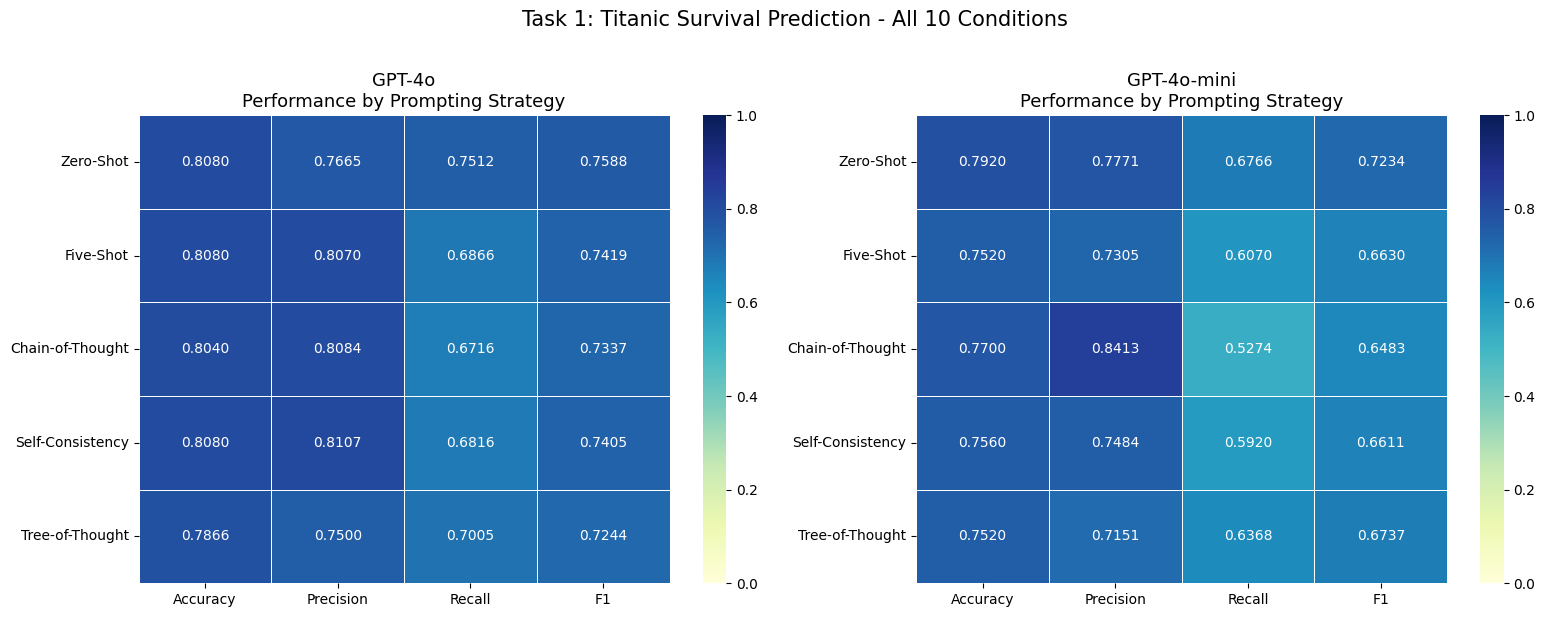

Heatmap saved.


In [ ]:
# ============================================
# VISUALIZATION 1: Performance Heatmaps
# ============================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
metrics_cols = ['Accuracy', 'Precision', 'Recall', 'F1']

for idx, model_name in enumerate(models.keys()):
    model_df  = results_df[results_df['Model'] == model_name].set_index('Prompting Method')
    sns.heatmap(
        model_df[metrics_cols], annot=True, fmt='.4f',
        cmap='YlGnBu', vmin=0, vmax=1,
        ax=axes[idx], linewidths=0.5
    )
    axes[idx].set_title(f'{model_name}\nPerformance by Prompting Strategy', fontsize=13)
    axes[idx].set_ylabel('')

plt.suptitle('Task 1: Titanic Survival Prediction - All 10 Conditions', fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/hw2_task1_heatmap.png', bbox_inches='tight', dpi=150)
plt.show()
print('Heatmap saved.')

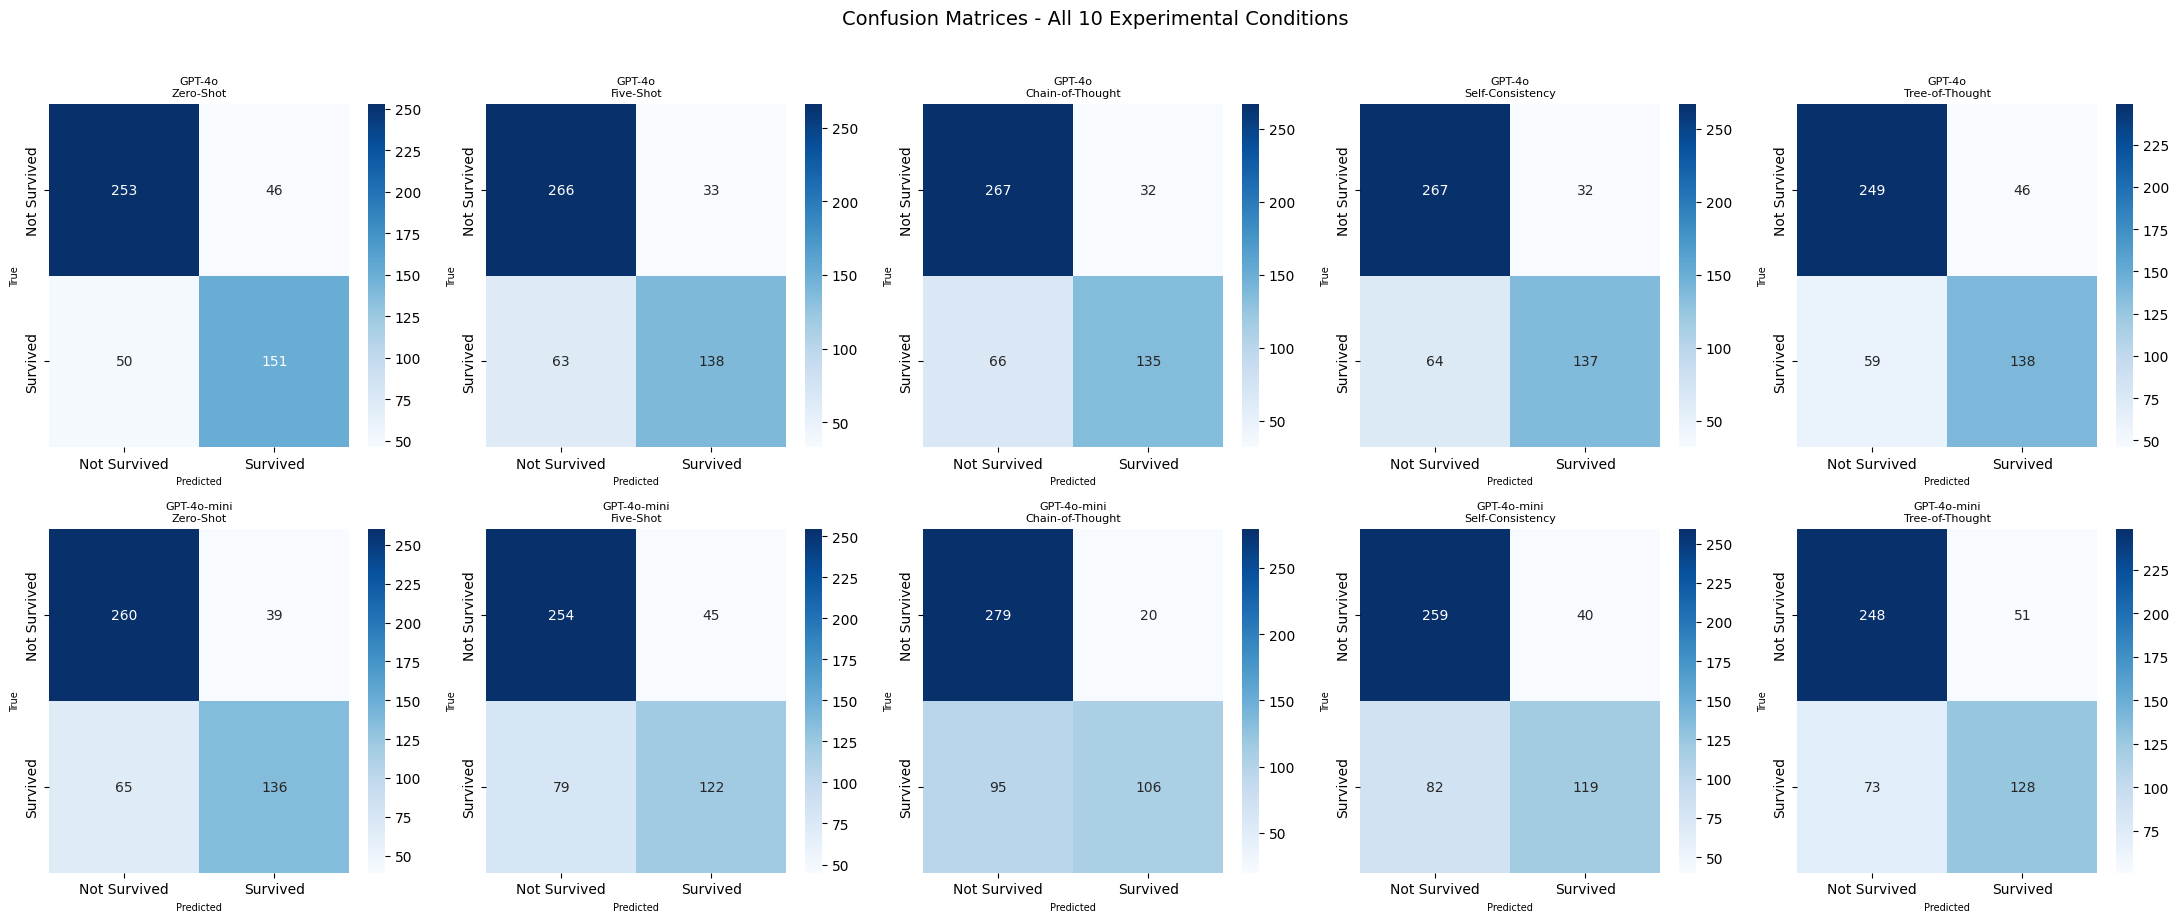

Confusion matrices saved.


In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(22, 9))

for row_idx, model_name in enumerate(models.keys()):
    for col_idx, strategy_name in enumerate(strategies.keys()):
        key       = f'{model_name}_{strategy_name}'
        preds     = all_predictions[key]
        valid_idx = [i for i, p in enumerate(preds) if p in [0, 1]]
        y_true    = [true_labels[i] for i in valid_idx]
        y_pred    = [preds[i] for i in valid_idx]
        if not y_pred:
            continue
        cm = confusion_matrix(y_true, y_pred)
        ax = axes[row_idx][col_idx]
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                    xticklabels=['Not Survived','Survived'],
                    yticklabels=['Not Survived','Survived'])
        ax.set_title(f'{model_name}\n{strategy_name}', fontsize=8)
        ax.set_ylabel('True', fontsize=7)
        ax.set_xlabel('Predicted', fontsize=7)

plt.suptitle('Confusion Matrices - All 10 Experimental Conditions', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/hw2_task1_confusion_matrices.png', bbox_inches='tight', dpi=150)
plt.show()
print('Confusion matrices saved.')

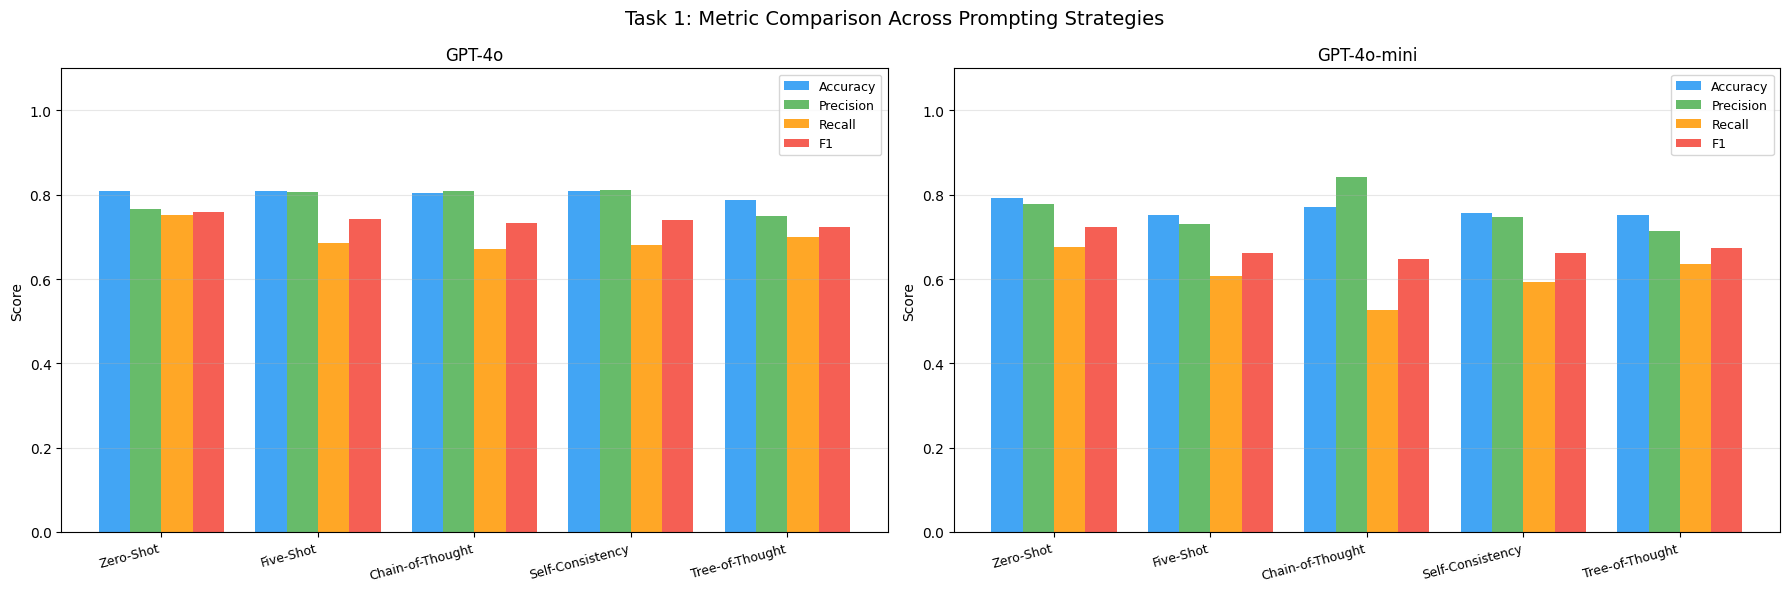

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
x      = np.arange(len(strategies))
width  = 0.2
colors = ['#2196F3', '#4CAF50', '#FF9800', '#F44336']

for ax_idx, model_name in enumerate(models.keys()):
    model_df = results_df[results_df['Model'] == model_name]
    for m_idx, metric in enumerate(['Accuracy','Precision','Recall','F1']):
        axes[ax_idx].bar(x + m_idx*width, model_df[metric].values,
                         width, label=metric, color=colors[m_idx], alpha=0.85)
    axes[ax_idx].set_xticks(x + width*1.5)
    axes[ax_idx].set_xticklabels(list(strategies.keys()), rotation=15, ha='right', fontsize=9)
    axes[ax_idx].set_ylim(0, 1.1)
    axes[ax_idx].set_title(model_name, fontsize=12)
    axes[ax_idx].set_ylabel('Score')
    axes[ax_idx].legend(fontsize=9)
    axes[ax_idx].grid(axis='y', alpha=0.3)

plt.suptitle('Task 1: Metric Comparison Across Prompting Strategies', fontsize=14)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/hw2_task1_bar_chart.png', bbox_inches='tight', dpi=150)
plt.show()

## 1.7 Hard Case Analysis

In [ ]:

misclassification_counts = np.zeros(N_SAMPLES)
for key, preds in all_predictions.items():
    for i, pred in enumerate(preds):
        if pred in [0, 1] and pred != true_labels[i]:
            misclassification_counts[i] += 1

hard_case_indices = np.argsort(misclassification_counts)[::-1][:15]
print('Top 15 hardest passengers:')
print(f'{"Idx":<6} {"Misclassified/10":<20} {"True Label"}')
print('-'*45)
for idx in hard_case_indices:
    lbl = 'Survived' if true_labels[idx]==1 else 'Not Survived'
    print(f'{idx:<6} {int(misclassification_counts[idx]):<20} {lbl}')

Top 15 hardest passengers:
Idx    Misclassified/10     True Label
---------------------------------------------
0      10                   Survived
326    10                   Survived
184    10                   Not Survived
193    10                   Survived
204    10                   Survived
372    10                   Survived
210    10                   Not Survived
156    10                   Survived
173    10                   Not Survived
203    10                   Survived
131    10                   Survived
108    10                   Survived
97     10                   Survived
443    10                   Survived
440    10                   Survived


In [ ]:
hard_cases_report = []

for idx in hard_case_indices[:10]:
    row        = df_eval.iloc[idx]
    true_label = true_labels[idx]
    pred_summary = {key: preds[idx] for key, preds in all_predictions.items()}

    causes = []
    if row['Pclass'] == 3 and true_label == 1:
        causes.append('3rd class who survived (against common pattern)')
    if row['Sex'] == 'male' and true_label == 1:
        causes.append('Male who survived (models bias: male=not survived)')
    if row['Sex'] == 'female' and true_label == 0:
        causes.append('Female who died (models bias: female=survived)')
    if row['Pclass'] == 1 and true_label == 0:
        causes.append('1st class who did not survive (against pattern)')
    if (row['SibSp'] + row['Parch']) > 3:
        causes.append('Large family complicates evacuation signal')
    if float(row['Age']) < 10:
        causes.append('Very young child - conflicting signals')
    if float(row['Age']) > 60:
        causes.append('Elderly passenger - conflicting signals')
    if not causes:
        causes.append('Conflicting feature signals / model reasoning error')

    hard_cases_report.append({
        'Passenger Index'         : idx,
        'True Label'              : true_label,
        'Pclass'                  : int(row['Pclass']),
        'Sex'                     : row['Sex'],
        'Age'                     : round(float(row['Age']), 1),
        'SibSp'                   : int(row['SibSp']),
        'Parch'                   : int(row['Parch']),
        'Fare'                    : round(float(row['Fare']), 2),
        'Misclassification Count' : int(misclassification_counts[idx]),
        'Likely Causes'           : ' | '.join(causes),
        'Predictions'             : pred_summary,
    })

hard_df = pd.DataFrame(hard_cases_report)
display_cols = ['Passenger Index','True Label','Pclass','Sex','Age','Fare',
                'Misclassification Count','Likely Causes']
print('=== HARD CASE ANALYSIS (10 Passengers) ===')
print(hard_df[display_cols].to_string(index=False))

=== HARD CASE ANALYSIS (10 Passengers) ===
 Passenger Index  True Label  Pclass    Sex  Age   Fare  Misclassification Count                                                                                        Likely Causes
               0           1       3   male 28.0  15.25                       10 3rd class who survived (against common pattern) | Male who survived (models bias: male=not survived)
             326           1       3   male 32.0   7.85                       10 3rd class who survived (against common pattern) | Male who survived (models bias: male=not survived)
             184           0       1   male 24.0 247.52                       10                                                      1st class who did not survive (against pattern)
             193           1       3   male 29.0   9.50                       10 3rd class who survived (against common pattern) | Male who survived (models bias: male=not survived)
             204           1       3   male 20.

In [ ]:

for i, case in enumerate(hard_cases_report[:10]):
    print(f'\n{"="*65}')
    print(f'HARD CASE #{i+1} | Passenger Index: {case["Passenger Index"]}')
    print(f'{"="*65}')
    print(format_passenger(df_eval.iloc[case['Passenger Index']], include_label=True))
    print(f'\nMisclassified by : {case["Misclassification Count"]}/10 conditions')
    print(f'Analysis         : {case["Likely Causes"]}')
    print('\nPredictions:')
    for cond_key, pred_val in case['Predictions'].items():
        status = '✓ CORRECT' if pred_val == case['True Label'] else '✗ WRONG'
        print(f'  {status} | {cond_key}: predicted={pred_val}')


HARD CASE #1 | Passenger Index: 0
Passenger Details:
- Ticket Class            : Third Class
- Sex                     : male
- Age                     : 28.0 years
- Siblings/Spouse aboard  : 1
- Parents/Children aboard : 1
- Fare paid               : $15.25
- Port of Embarkation     : Cherbourg
Outcome: Survived (label: 1)

Misclassified by : 10/10 conditions
Analysis         : 3rd class who survived (against common pattern) | Male who survived (models bias: male=not survived)

Predictions:
  ✗ WRONG | GPT-4o_Zero-Shot: predicted=0
  ✗ WRONG | GPT-4o_Five-Shot: predicted=0
  ✗ WRONG | GPT-4o_Chain-of-Thought: predicted=0
  ✗ WRONG | GPT-4o_Self-Consistency: predicted=0
  ✗ WRONG | GPT-4o_Tree-of-Thought: predicted=0
  ✗ WRONG | GPT-4o-mini_Zero-Shot: predicted=0
  ✗ WRONG | GPT-4o-mini_Five-Shot: predicted=0
  ✗ WRONG | GPT-4o-mini_Chain-of-Thought: predicted=0
  ✗ WRONG | GPT-4o-mini_Self-Consistency: predicted=0
  ✗ WRONG | GPT-4o-mini_Tree-of-Thought: predicted=0

HARD CASE #2 | 



# **TASK 2: ENTERPRISE RAG WITH WixQA**

### Part 1: Baseline RAG + Hyperparameter Tuning on WixQA-Synthetic
### Part 2: Retrieval Evaluation on Expert + Simulated
### Part 3: Generation Evaluation on Expert + Simulated
### Part 4: System Improvements (Semantic Chunking, Reranking, Query Rewriting)

## 2.1 Load WixQA Datasets

In [ ]:
from datasets import load_dataset

print('Loading WixQA Knowledge Base...')
kb_dataset  = load_dataset('Wix/WixQA', 'wix_kb_corpus', split='train')
kb_articles = [item['contents'] for item in kb_dataset]  # 'contents' not 'text'
print(f'Loaded {len(kb_articles)} articles.')

print('\nLoading WixQA-Synthetic...')
wix_synthetic = load_dataset('Wix/WixQA', 'wixqa_synthetic', split='train').to_pandas()
print(f'WixQA-Synthetic: {len(wix_synthetic)} queries')

print('\nLoading WixQA-ExpertWritten...')
wix_expert = load_dataset('Wix/WixQA', 'wixqa_expertwritten', split='train').to_pandas()
print(f'WixQA-ExpertWritten: {len(wix_expert)} queries')

print('\nLoading WixQA-Simulated...')
wix_simulated = load_dataset('Wix/WixQA', 'wixqa_simulated', split='train').to_pandas()
print(f'WixQA-Simulated: {len(wix_simulated)} queries')

print('\nAll datasets loaded successfully!')
print(wix_synthetic.head(2))

Loading WixQA Knowledge Base...
Loaded 6221 articles.

Loading WixQA-Synthetic...
WixQA-Synthetic: 6221 queries

Loading WixQA-ExpertWritten...
WixQA-ExpertWritten: 200 queries

Loading WixQA-Simulated...
WixQA-Simulated: 200 queries

All datasets loaded successfully!
                                            question  \
0  How can I manage inventory updates after creat...   
1  How can I create and send purchase orders usin...   

                                              answer  \
0  When you mark the merchandise as received in t...   
1  We're excited to announce that it's now possib...   

                                         article_ids  
0  [9c2c7c359c723590c8fe2c0e2d49abb9cfdc95990524d...  
1  [898b43cf76a908dd88e43830ff4e4244f1bc66f0217f2...  


## 2.2 Chunking Functions

In [ ]:

from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

EMBED_MODEL_NAME = 'sentence-transformers/all-MiniLM-L6-v2'
embed_model      = SentenceTransformer(EMBED_MODEL_NAME)
print(f'Embedding model loaded: {EMBED_MODEL_NAME}')


def semantic_chunk_article(article, threshold=0.5, max_chunk_size=400):
    sentences = [s.strip() for s in article.split('. ') if s.strip()]
    if len(sentences) <= 1:
        return [article]
    embeddings    = embed_model.encode(sentences, show_progress_bar=False)
    chunks        = []
    current_chunk = [sentences[0]]
    for i in range(1, len(sentences)):
        sim = cosine_similarity(
            embeddings[i-1].reshape(1,-1), embeddings[i].reshape(1,-1)
        )[0][0]
        if sim >= threshold and len('. '.join(current_chunk)) < max_chunk_size:
            current_chunk.append(sentences[i])
        else:
            chunks.append('. '.join(current_chunk))
            current_chunk = [sentences[i]]
    if current_chunk:
        chunks.append('. '.join(current_chunk))
    return chunks


def semantic_chunk_all_articles(articles):
    all_chunks = []
    for art_id, article in enumerate(tqdm(articles, desc='Semantic chunking')):
        for cid, chunk in enumerate(semantic_chunk_article(article)):
            all_chunks.append({
                'text': chunk, 'article_id': art_id,
                'chunk_id': f'sem_art{art_id}_c{cid}'
            })
    return all_chunks


print('Semantic chunking defined.')

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Embedding model loaded: sentence-transformers/all-MiniLM-L6-v2
Semantic chunking defined.


## 2.3 FAISS Vector Store

In [ ]:

import faiss

def build_faiss_index(chunks, batch_size=256):
    chunk_texts    = [c['text'] for c in chunks]
    all_embeddings = []
    print(f'Embedding {len(chunk_texts)} chunks...')
    for i in tqdm(range(0, len(chunk_texts), batch_size), desc='Embedding'):
        embs = embed_model.encode(chunk_texts[i:i+batch_size], show_progress_bar=False)
        all_embeddings.append(embs)
    embeddings = np.vstack(all_embeddings).astype('float32')
    faiss.normalize_L2(embeddings)
    index = faiss.IndexFlatIP(embeddings.shape[1])
    index.add(embeddings)
    print(f'Index built: {index.ntotal} vectors, dim={embeddings.shape[1]}')
    return index, chunk_texts


def retrieve_top_k(query, index, chunk_texts, k=5):
    q_emb = embed_model.encode([query], show_progress_bar=False).astype('float32')
    faiss.normalize_L2(q_emb)
    _, indices = index.search(q_emb, k)
    return [chunk_texts[i] for i in indices[0]]


print('FAISS functions defined.')

FAISS functions defined.


## 2.4 RAG Generator

In [ ]:

RAG_SYSTEM = (
    'You are a helpful Wix customer support assistant. '
    'Answer the question using ONLY the provided context. '
    'If context is insufficient, say: "I do not have enough information to answer this question." '
    'Be concise and factual.'
)

def generate_rag_answer(query, retrieved_chunks, model=MODEL_1):
    context  = '\n\n---\n\n'.join(retrieved_chunks)
    user_msg = f'Context:\n{context}\n\nQuestion: {query}\n\nAnswer:'
    try:
        resp = client.chat.completions.create(
            model=model,
            messages=[
                {'role': 'system', 'content': RAG_SYSTEM},
                {'role': 'user',   'content': user_msg}
            ],
            temperature=0.0,
            max_tokens=300
        )
        return resp.choices[0].message.content.strip()
    except Exception as e:
        return f'ERROR: {e}'


print('RAG generator defined.')

RAG generator defined.


## 2.5 Evaluation Metrics (F1, ROUGE, Context Recall, Factuality)

In [ ]:

rouge = rouge_scorer.RougeScorer(['rouge1','rouge2'], use_stemmer=True)


def compute_token_f1(pred, gt):
    p_tok = pred.lower().split()
    g_tok = gt.lower().split()
    if not p_tok or not g_tok:
        return 0.0
    common = sum((Counter(p_tok) & Counter(g_tok)).values())
    if common == 0:
        return 0.0
    prec = common / len(p_tok)
    rec  = common / len(g_tok)
    return 2 * prec * rec / (prec + rec)


def compute_rouge(pred, gt):
    s = rouge.score(gt, pred)
    return {'rouge1': s['rouge1'].fmeasure, 'rouge2': s['rouge2'].fmeasure}


def compute_context_recall(query, gt, retrieved, model=MODEL_1):
    """LLM-as-judge (temp=0): Does retrieved context suffice to answer query?"""
    ctx     = '\n\n'.join(retrieved)
    prompt  = (
        f'Question: {query}\n\n'
        f'Ground-truth answer: {gt}\n\n'
        f'Retrieved context:\n{ctx}\n\n'
        f'Does the retrieved context contain sufficient information to answer the question correctly?\n'
        f'Respond with ONLY "Yes" or "No".'
    )
    try:
        resp = client.chat.completions.create(
            model=model,
            messages=[{'role':'user','content':prompt}],
            temperature=0.0, max_tokens=5
        )
        return 1 if 'yes' in resp.choices[0].message.content.strip().lower() else 0
    except:
        return 0


def compute_factuality(generated, gt, model=MODEL_1):
    """LLM-as-judge: Does generated answer preserve essential meaning of ground truth?"""
    prompt = (
        f'Ground-truth answer: {gt}\n\n'
        f'Generated answer: {generated}\n\n'
        f'Does the generated answer preserve the essential meaning of the ground-truth answer '
        f'without any contradiction or hallucination?\n'
        f'Respond with ONLY "1" (yes) or "0" (no).'
    )
    try:
        resp = client.chat.completions.create(
            model=model,
            messages=[{'role':'user','content':prompt}],
            temperature=0.0, max_tokens=5
        )
        return 1 if '1' in resp.choices[0].message.content.strip() else 0
    except:
        return 0


print('All evaluation metrics defined.')

All evaluation metrics defined.


In [ ]:
# ============================================
# DEFINE CHUNKING FUNCTION (no langchain needed)
# ============================================
def fixed_chunk_articles(articles, chunk_size=300, overlap=30):
    all_chunks = []
    for art_id, article in enumerate(articles):
        words  = article.split()
        chunks = []
        start  = 0
        while start < len(words):
            end   = start + chunk_size
            chunk = ' '.join(words[start:end])
            chunks.append(chunk)
            start = start + chunk_size - overlap
        for cid, chunk in enumerate(chunks):
            all_chunks.append({
                'text'      : chunk,
                'article_id': art_id,
                'chunk_id'  : f'art{art_id}_c{cid}'
            })
    return all_chunks

# Test it
test = fixed_chunk_articles(kb_articles[:2], chunk_size=300, overlap=30)
print(f'Test: 2 articles → {len(test)} chunks')
print(f'Sample: {test[0]["text"][:150]}')

# Continue with hyperparameter search
N_DEV       = min(50, len(wix_synthetic))
dev_queries = wix_synthetic['question'].tolist()[:N_DEV]
dev_answers = wix_synthetic['answer'].tolist()[:N_DEV]

print(f'Dev queries loaded: {N_DEV}')

Test: 2 articles → 3 chunks
Sample: Wix Events: About the Event Details and Registration Form Pages Guests visiting your site view the events you offer on the Events List page. From ther
Dev queries loaded: 50


## 2.6 Part 1 — Baseline RAG Hyperparameter Search

In [ ]:

N_DEV       = min(50, len(wix_synthetic))
dev_queries = wix_synthetic['question'].tolist()[:N_DEV]
dev_answers = wix_synthetic['answer'].tolist()[:N_DEV]

chunk_sizes      = [300, 500]
overlaps         = [30, 60]
k_values         = [1, 3, 5, 10]
hyperparam_results = []

for chunk_size in chunk_sizes:
    for overlap in overlaps:
        print(f'\nBuilding index: chunk_size={chunk_size}, overlap={overlap}...')
        chunks = fixed_chunk_articles(kb_articles, chunk_size=chunk_size, overlap=overlap)
        index, chunk_texts = build_faiss_index(chunks)

        for k in k_values:
            cr_list, f1_list, r1_list = [], [], []
            for q, gt in tqdm(zip(dev_queries, dev_answers),
                              total=N_DEV, desc=f'  k={k}'):
                retrieved = retrieve_top_k(q, index, chunk_texts, k=k)
                generated = generate_rag_answer(q, retrieved)
                cr_list.append(compute_context_recall(q, gt, retrieved))
                f1_list.append(compute_token_f1(generated, gt))
                r1_list.append(compute_rouge(generated, gt)['rouge1'])
                time.sleep(0.4)

            result = {
                'Chunk Size'    : chunk_size,
                'Overlap'       : overlap,
                'k'             : k,
                'Context Recall': round(np.mean(cr_list), 4),
                'F1'            : round(np.mean(f1_list),  4),
                'ROUGE-1'       : round(np.mean(r1_list),  4),
            }
            hyperparam_results.append(result)
            print(f'  chunk={chunk_size} overlap={overlap} k={k} '
                  f'CR={result["Context Recall"]:.3f} F1={result["F1"]:.3f} '
                  f'R1={result["ROUGE-1"]:.3f}')

hp_df = pd.DataFrame(hyperparam_results)
hp_df.to_csv('/content/drive/MyDrive/hw2_hyperparam_results.csv', index=False)
print('\nHyperparameter search complete. Results saved.')


Building index: chunk_size=300, overlap=30...
Embedding 12371 chunks...


Embedding: 100%|██████████| 49/49 [00:24<00:00,  1.96it/s]


Index built: 12371 vectors, dim=384


  k=1: 100%|██████████| 50/50 [01:51<00:00,  2.22s/it]


  chunk=300 overlap=30 k=1 CR=0.980 F1=0.475 R1=0.537


  k=3: 100%|██████████| 50/50 [02:11<00:00,  2.63s/it]


... (31 outputs left out)

  k=5: 100%|██████████| 50/50 [06:13<00:00,  7.47s/it]


  chunk=500 overlap=60 k=5 CR=0.980 F1=0.513 R1=0.581


  k=10: 100%|██████████| 50/50 [11:03<00:00, 13.27s/it]

  chunk=500 overlap=60 k=10 CR=0.940 F1=0.528 R1=0.593

Hyperparameter search complete. Results saved.


In [ ]:

hp_df = pd.read_csv('/content/drive/MyDrive/hw2_hyperparam_results.csv')

def make_obs(row):
    parts = []
    if row['Context Recall'] >= 0.7:   parts.append('High recall')
    elif row['Context Recall'] < 0.4:  parts.append('Low recall')
    else:                              parts.append('Moderate recall')
    if row['k'] == 1:   parts.append('limited coverage')
    if row['k'] == 10:  parts.append('may add noise')
    if row['F1'] >= 0.4: parts.append('strong F1')
    return '; '.join(parts)

hp_df['Observation'] = hp_df.apply(make_obs, axis=1)
print(' HYPERPARAMETER SEARCH RESULTS (WixQA-Synthetic) ')
print(hp_df.to_string(index=False))

 HYPERPARAMETER SEARCH RESULTS (WixQA-Synthetic) 
 Chunk Size  Overlap  k  Context Recall     F1  ROUGE-1                              Observation
        300       30  1            0.98 0.4748   0.5370 High recall; limited coverage; strong F1
        300       30  3            0.98 0.5111   0.5815                   High recall; strong F1
        300       30  5            0.94 0.5097   0.5749                   High recall; strong F1
        300       30 10            0.90 0.4955   0.5649    High recall; may add noise; strong F1
        300       60  1            1.00 0.4806   0.5404 High recall; limited coverage; strong F1
        300       60  3            1.00 0.5443   0.6211                   High recall; strong F1
        300       60  5            0.98 0.5272   0.6004                   High recall; strong F1
        300       60 10            1.00 0.5006   0.5680    High recall; may add noise; strong F1
        500       30  1            1.00 0.4878   0.5577 High recall; limited 

In [ ]:

hp_df['Composite']   = 0.4*hp_df['Context Recall'] + 0.3*hp_df['F1'] + 0.3*hp_df['ROUGE-1']
best                 = hp_df.loc[hp_df['Composite'].idxmax()]
OPTIMAL_CHUNK_SIZE   = int(best['Chunk Size'])
OPTIMAL_OVERLAP      = int(best['Overlap'])
OPTIMAL_K            = int(best['k'])

print('OPTIMAL CONFIGURATION')
print(f'Chunk Size     : {OPTIMAL_CHUNK_SIZE}')
print(f'Overlap        : {OPTIMAL_OVERLAP}')
print(f'k              : {OPTIMAL_K}')
print(f'Context Recall : {best["Context Recall"]:.4f}')
print(f'F1             : {best["F1"]:.4f}')
print(f'ROUGE-1        : {best["ROUGE-1"]:.4f}')

print('\n BASELINE SYSTEM CONFIGURATION TABLE ')
config_df = pd.DataFrame([
    {'Component': 'Chunk size / overlap',    'Configuration Used': f'{OPTIMAL_CHUNK_SIZE} / {OPTIMAL_OVERLAP}'},
    {'Component': 'Embedding model',          'Configuration Used': EMBED_MODEL_NAME},
    {'Component': 'Vector database',          'Configuration Used': 'FAISS (IndexFlatIP, L2-normalized)'},
    {'Component': 'Retriever type',           'Configuration Used': 'Dense vector retrieval (cosine similarity)'},
    {'Component': 'Generator model',          'Configuration Used': MODEL_1},
    {'Component': 'Prompting strategy',       'Configuration Used': 'Grounded generation with retrieved context only'},
])
print(config_df.to_string(index=False))

OPTIMAL CONFIGURATION
Chunk Size     : 300
Overlap        : 60
k              : 3
Context Recall : 1.0000
F1             : 0.5443
ROUGE-1        : 0.6211

 BASELINE SYSTEM CONFIGURATION TABLE 
           Component                              Configuration Used
Chunk size / overlap                                        300 / 60
     Embedding model          sentence-transformers/all-MiniLM-L6-v2
     Vector database              FAISS (IndexFlatIP, L2-normalized)
      Retriever type      Dense vector retrieval (cosine similarity)
     Generator model                                          gpt-4o
  Prompting strategy Grounded generation with retrieved context only


In [ ]:

print(f'Building optimal baseline index (chunk={OPTIMAL_CHUNK_SIZE}, overlap={OPTIMAL_OVERLAP})...')
baseline_chunks              = fixed_chunk_articles(
    kb_articles, chunk_size=OPTIMAL_CHUNK_SIZE, overlap=OPTIMAL_OVERLAP
)
baseline_index, baseline_chunk_texts = build_faiss_index(baseline_chunks)

faiss.write_index(baseline_index, '/content/drive/MyDrive/hw2_baseline_index.faiss')
with open('/content/drive/MyDrive/hw2_baseline_chunks.json', 'w') as f:
    json.dump(baseline_chunk_texts, f)
print(f'Baseline index saved. Total chunks: {len(baseline_chunks)}')

Building optimal baseline index (chunk=300, overlap=60)...
Embedding 13386 chunks...


Embedding: 100%|██████████| 53/53 [00:26<00:00,  2.01it/s]


Index built: 13386 vectors, dim=384
Baseline index saved. Total chunks: 13386


## 2.7 Part 2 — Retrieval Evaluation

In [ ]:
N_EVAL = 100

def eval_retrieval(dataset_df, index, chunk_texts, k, name, n=None):
    if n:
        dataset_df = dataset_df.sample(min(n, len(dataset_df)), random_state=42)
    recalls = []
    for _, row in tqdm(dataset_df.iterrows(), total=len(dataset_df), desc=f'CR [{name}]'):
        retrieved = retrieve_top_k(row['question'], index, chunk_texts, k=k)
        recalls.append(compute_context_recall(row['question'], row['answer'], retrieved))
        time.sleep(0.3)
    return round(np.mean(recalls), 4)

print('Evaluating ExpertWritten...')
cr_expert = eval_retrieval(wix_expert, baseline_index, baseline_chunk_texts, OPTIMAL_K, 'Expert', N_EVAL)
print('Evaluating Simulated...')
cr_simulated = eval_retrieval(wix_simulated, baseline_index, baseline_chunk_texts, OPTIMAL_K, 'Simulated', N_EVAL)

retrieval_results = pd.DataFrame([
    {'Dataset': 'WixQA-ExpertWritten', 'Optimal Chunk': OPTIMAL_CHUNK_SIZE,
     'Optimal Overlap': OPTIMAL_OVERLAP, 'Optimal k': OPTIMAL_K,
     'Context Recall': cr_expert,
     'Brief Observation': 'Good coverage' if cr_expert>0.6 else 'Some queries lack context'},
    {'Dataset': 'WixQA-Simulated', 'Optimal Chunk': OPTIMAL_CHUNK_SIZE,
     'Optimal Overlap': OPTIMAL_OVERLAP, 'Optimal k': OPTIMAL_K,
     'Context Recall': cr_simulated,
     'Brief Observation': 'Varied retrieval' if cr_simulated<cr_expert else 'Consistent retrieval'},
])

print('\n=== PART 2: RETRIEVAL EVALUATION ===')
print(retrieval_results.to_string(index=False))

Evaluating ExpertWritten...


CR [Expert]: 100%|██████████| 100/100 [02:27<00:00,  1.48s/it]


Evaluating Simulated...


CR [Simulated]: 100%|██████████| 100/100 [02:35<00:00,  1.55s/it]


=== PART 2: RETRIEVAL EVALUATION ===
            Dataset  Optimal Chunk  Optimal Overlap  Optimal k  Context Recall Brief Observation
WixQA-ExpertWritten            300               60          3            0.99     Good coverage
    WixQA-Simulated            300               60          3            0.89  Varied retrieval


## 2.8 Part 3 — Generation Evaluation

In [ ]:

def eval_generation(dataset_df, index, chunk_texts, k, name, n=None):
    if n:
        dataset_df = dataset_df.sample(min(n, len(dataset_df)), random_state=42)
    f1s, r1s, r2s, fcs = [], [], [], []
    for _, row in tqdm(dataset_df.iterrows(), total=len(dataset_df), desc=f'Gen [{name}]'):
        q         = row['question']
        gt        = row['answer']
        retrieved = retrieve_top_k(q, index, chunk_texts, k=k)
        generated = generate_rag_answer(q, retrieved)
        rg        = compute_rouge(generated, gt)
        f1s.append(compute_token_f1(generated, gt))
        r1s.append(rg['rouge1'])
        r2s.append(rg['rouge2'])
        fcs.append(compute_factuality(generated, gt))
        time.sleep(0.5)
    return {
        'F1': round(np.mean(f1s),4), 'ROUGE-1': round(np.mean(r1s),4),
        'ROUGE-2': round(np.mean(r2s),4), 'Factuality': round(np.mean(fcs),4)
    }


print('Evaluating generation on ExpertWritten...')
gen_expert = eval_generation(wix_expert, baseline_index, baseline_chunk_texts, OPTIMAL_K, 'Expert', N_EVAL)
print('\nEvaluating generation on Simulated...')
gen_sim    = eval_generation(wix_simulated, baseline_index, baseline_chunk_texts, OPTIMAL_K, 'Simulated', N_EVAL)

gen_results = pd.DataFrame([
    {'Dataset': 'WixQA-ExpertWritten', **gen_expert},
    {'Dataset': 'WixQA-Simulated',     **gen_sim},
])
print('\n=== PART 3: GENERATION EVALUATION ===')
print(gen_results.to_string(index=False))

Evaluating generation on ExpertWritten...


Gen [Expert]: 100%|██████████| 100/100 [03:53<00:00,  2.34s/it]



Evaluating generation on Simulated...


Gen [Simulated]: 100%|██████████| 100/100 [03:15<00:00,  1.96s/it]


=== PART 3: GENERATION EVALUATION ===
            Dataset     F1  ROUGE-1  ROUGE-2  Factuality
WixQA-ExpertWritten 0.2584   0.2827   0.1739        0.34
    WixQA-Simulated 0.1735   0.2057   0.1086        0.27


## 2.9 Part 4 — System Improvements

In [ ]:

print('Building semantic chunking index...')
semantic_chunks              = semantic_chunk_all_articles(kb_articles)
semantic_index, semantic_chunk_texts = build_faiss_index(semantic_chunks)
faiss.write_index(semantic_index, '/content/drive/MyDrive/hw2_semantic_index.faiss')
with open('/content/drive/MyDrive/hw2_semantic_chunks.json','w') as f:
    json.dump(semantic_chunk_texts, f)
print(f'Semantic index saved. Total chunks: {len(semantic_chunks)}')

Building semantic chunking index...


Semantic chunking: 100%|██████████| 6221/6221 [02:02<00:00, 50.70it/s]


Embedding 61877 chunks...


Embedding: 100%|██████████| 242/242 [00:47<00:00,  5.15it/s]


Index built: 61877 vectors, dim=384
Semantic index saved. Total chunks: 61877


In [ ]:

from sentence_transformers import CrossEncoder

cross_encoder = CrossEncoder('cross-encoder/ms-marco-MiniLM-L-6-v2')

def retrieve_with_reranking(query, index, chunk_texts, k=5, top_n=50):
    candidates = retrieve_top_k(query, index, chunk_texts, k=top_n)
    scores     = cross_encoder.predict([[query, c] for c in candidates])
    ranked     = sorted(zip(scores, candidates), key=lambda x: x[0], reverse=True)
    return [c for _, c in ranked[:k]]

print('Cross-encoder reranker loaded.')

config.json:   0%|          | 0.00/794 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: cross-encoder/ms-marco-MiniLM-L-6-v2
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

Cross-encoder reranker loaded.


In [ ]:

def rewrite_query(query, model=MODEL_1):
    prompt = (
        f'Rewrite this customer support question as a concise retrieval-optimized search query. '
        f'Focus on key technical terms. Output only the rewritten query.\n\n'
        f'Original: {query}\nRewritten:'
    )
    try:
        resp = client.chat.completions.create(
            model=model, messages=[{'role':'user','content':prompt}],
            temperature=0.0, max_tokens=100
        )
        return resp.choices[0].message.content.strip()
    except:
        return query

print('Query rewriter defined.')

Query rewriter defined.


In [ ]:

N_COMP = 100

def run_full_eval(dataset_df, dataset_name, index, chunk_texts, k,
                  use_reranking=False, use_query_rewriting=False, n=None):
    if n:
        dataset_df = dataset_df.sample(min(n, len(dataset_df)), random_state=42)
    cr_l, f1_l, r1_l, r2_l, fc_l = [], [], [], [], []
    for _, row in tqdm(dataset_df.iterrows(), total=len(dataset_df), desc=dataset_name):
        q  = row['question']
        gt = row['answer']
        q_search  = rewrite_query(q) if use_query_rewriting else q
        retrieved = (retrieve_with_reranking(q_search, index, chunk_texts, k=k)
                     if use_reranking else
                     retrieve_top_k(q_search, index, chunk_texts, k=k))
        generated = generate_rag_answer(q, retrieved)
        rg        = compute_rouge(generated, gt)
        cr_l.append(compute_context_recall(q, gt, retrieved))
        f1_l.append(compute_token_f1(generated, gt))
        r1_l.append(rg['rouge1'])
        r2_l.append(rg['rouge2'])
        fc_l.append(compute_factuality(generated, gt))
        time.sleep(0.5)
    return {
        'Dataset'        : dataset_name,
        'Context Recall' : round(np.mean(cr_l), 4),
        'F1'             : round(np.mean(f1_l), 4),
        'ROUGE-1'        : round(np.mean(r1_l), 4),
        'ROUGE-2'        : round(np.mean(r2_l), 4),
        'Factuality'     : round(np.mean(fc_l), 4),
    }


comparison_results = []
eval_sets = [('WixQA-ExpertWritten', wix_expert), ('WixQA-Simulated', wix_simulated)]

for i, (ds_name, ds_df) in enumerate(eval_sets):
    print(f'\n[{i*4+1}/8] Baseline RAG - {ds_name}')
    comparison_results.append({'System': 'Baseline RAG',
        **run_full_eval(ds_df, ds_name, baseline_index, baseline_chunk_texts, OPTIMAL_K, n=N_COMP)})

    print(f'[{i*4+2}/8] Semantic Chunking - {ds_name}')
    comparison_results.append({'System': '+ Semantic Chunking',
        **run_full_eval(ds_df, ds_name, semantic_index, semantic_chunk_texts, OPTIMAL_K, n=N_COMP)})

    print(f'[{i*4+3}/8] Reranking - {ds_name}')
    comparison_results.append({'System': '+ Reranking',
        **run_full_eval(ds_df, ds_name, baseline_index, baseline_chunk_texts, OPTIMAL_K,
                        use_reranking=True, n=N_COMP)})

    print(f'[{i*4+4}/8] Query Rewriting - {ds_name}')
    comparison_results.append({'System': '+ Query Rewriting',
        **run_full_eval(ds_df, ds_name, baseline_index, baseline_chunk_texts, OPTIMAL_K,
                        use_query_rewriting=True, n=N_COMP)})

comparison_df = pd.DataFrame(comparison_results)
comparison_df.to_csv('/content/drive/MyDrive/hw2_comparison_results.csv', index=False)
print('\nAll comparison results saved.')


[1/8] Baseline RAG - WixQA-ExpertWritten


WixQA-ExpertWritten: 100%|██████████| 100/100 [06:28<00:00,  3.89s/it]


[2/8] Semantic Chunking - WixQA-ExpertWritten


WixQA-ExpertWritten: 100%|██████████| 100/100 [04:02<00:00,  2.43s/it]


[3/8] Reranking - WixQA-ExpertWritten


WixQA-ExpertWritten: 100%|██████████| 100/100 [07:54<00:00,  4.74s/it]


... (7 outputs left out)

WixQA-Simulated: 100%|██████████| 100/100 [05:43<00:00,  3.44s/it]


[8/8] Query Rewriting - WixQA-Simulated


WixQA-Simulated: 100%|██████████| 100/100 [05:53<00:00,  3.54s/it]


All comparison results saved.


In [ ]:

print('PART 4: SYSTEM IMPROVEMENTS COMPARISON ')
print(comparison_df.to_string(index=False))

PART 4: SYSTEM IMPROVEMENTS COMPARISON 
             System             Dataset  Context Recall     F1  ROUGE-1  ROUGE-2  Factuality
       Baseline RAG WixQA-ExpertWritten            0.96 0.2633   0.2877   0.1765        0.34
+ Semantic Chunking WixQA-ExpertWritten            0.89 0.1688   0.1831   0.0892        0.10
        + Reranking WixQA-ExpertWritten            1.00 0.2643   0.2843   0.1761        0.36
  + Query Rewriting WixQA-ExpertWritten            0.96 0.2402   0.2617   0.1581        0.32
       Baseline RAG     WixQA-Simulated            0.89 0.1725   0.2065   0.1042        0.26
+ Semantic Chunking     WixQA-Simulated            0.67 0.1482   0.1759   0.0725        0.10
        + Reranking     WixQA-Simulated            0.97 0.1891   0.2302   0.1259        0.30
  + Query Rewriting     WixQA-Simulated            0.88 0.1567   0.1842   0.0946        0.25


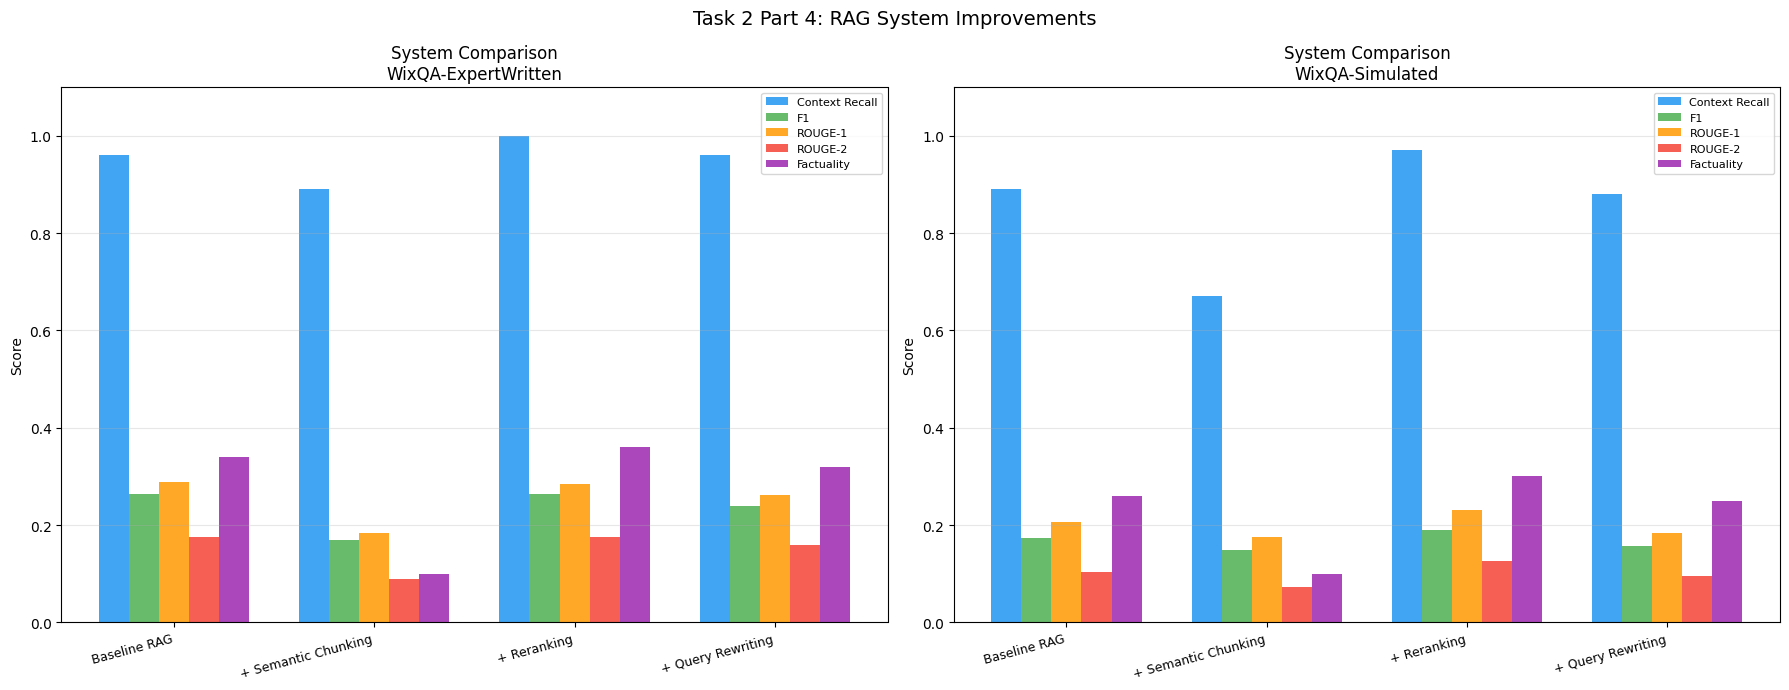

Comparison chart saved.


In [ ]:
metrics      = ['Context Recall','F1','ROUGE-1','ROUGE-2','Factuality']
system_names = comparison_df['System'].unique()
colors       = ['#2196F3','#4CAF50','#FF9800','#F44336','#9C27B0']

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax_idx, (ds_name, _) in enumerate(eval_sets):
    subset = comparison_df[comparison_df['Dataset'] == ds_name]
    x      = np.arange(len(system_names))
    width  = 0.15
    for m_idx, metric in enumerate(metrics):
        vals = [subset[subset['System']==s][metric].values[0]
                if len(subset[subset['System']==s])>0 else 0
                for s in system_names]
        axes[ax_idx].bar(x + m_idx*width, vals, width,
                         label=metric, color=colors[m_idx], alpha=0.85)
    axes[ax_idx].set_xticks(x + width*2)
    axes[ax_idx].set_xticklabels(system_names, rotation=15, ha='right', fontsize=9)
    axes[ax_idx].set_ylim(0, 1.1)
    axes[ax_idx].set_title(f'System Comparison\n{ds_name}', fontsize=12)
    axes[ax_idx].set_ylabel('Score')
    axes[ax_idx].legend(fontsize=8)
    axes[ax_idx].grid(axis='y', alpha=0.3)

plt.suptitle('Task 2 Part 4: RAG System Improvements', fontsize=14)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/hw2_task2_comparison.png', bbox_inches='tight', dpi=150)
plt.show()
print('Comparison chart saved.')

---
## FINAL RESULTS SUMMARY

In [ ]:
print('=' * 70)
print('DATA 266 - HW2 - COMPLETE RESULTS SUMMARY')
print('=' * 70)

print('\n--- TASK 1: TITANIC PROMPTING (10 Conditions) ---')
print('Models: GPT-4.1 and GPT-4o | Test set: 500 passengers')
print(results_df[['Model','Prompting Method','Accuracy','Precision','Recall','F1']].to_string(index=False))

print('\n--- TASK 2 PART 1: SYSTEM CONFIGURATION ---')
print(config_df.to_string(index=False))

print('\n--- TASK 2 PART 2: RETRIEVAL EVALUATION ---')
print(retrieval_results[['Dataset','Context Recall','Brief Observation']].to_string(index=False))

print('\n--- TASK 2 PART 3: GENERATION EVALUATION ---')
print(gen_results.to_string(index=False))

print('\n--- TASK 2 PART 4: SYSTEM IMPROVEMENTS ---')
print(comparison_df.to_string(index=False))

print('\n' + '=' * 70)
print('Files saved to Google Drive:')
files = [
    'hw2_titanic_predictions.json',
    'hw2_hyperparam_results.csv',
    'hw2_comparison_results.csv',
    'hw2_task1_heatmap.png',
    'hw2_task1_confusion_matrices.png',
    'hw2_task1_bar_chart.png',
    'hw2_task2_comparison.png',
    'hw2_baseline_index.faiss',
    'hw2_semantic_index.faiss',
]
for f in files:
    print(f'  - {f}')

DATA 266 - HW2 - COMPLETE RESULTS SUMMARY

--- TASK 1: TITANIC PROMPTING (10 Conditions) ---
Models: GPT-4.1 and GPT-4o | Test set: 500 passengers
      Model Prompting Method  Accuracy  Precision  Recall     F1
     GPT-4o        Zero-Shot    0.8080     0.7665  0.7512 0.7588
     GPT-4o        Five-Shot    0.8080     0.8070  0.6866 0.7419
     GPT-4o Chain-of-Thought    0.8040     0.8084  0.6716 0.7337
     GPT-4o Self-Consistency    0.8080     0.8107  0.6816 0.7405
     GPT-4o  Tree-of-Thought    0.7866     0.7500  0.7005 0.7244
GPT-4o-mini        Zero-Shot    0.7920     0.7771  0.6766 0.7234
GPT-4o-mini        Five-Shot    0.7520     0.7305  0.6070 0.6630
GPT-4o-mini Chain-of-Thought    0.7700     0.8413  0.5274 0.6483
GPT-4o-mini Self-Consistency    0.7560     0.7484  0.5920 0.6611
GPT-4o-mini  Tree-of-Thought    0.7520     0.7151  0.6368 0.6737

--- TASK 2 PART 1: SYSTEM CONFIGURATION ---
           Component                              Configuration Used
Chunk size / overlap    